# Member 1: Research Questions

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11})

# Load integrated dataset
df_cd = pd.read_csv("../outputs/member3_integration/cd_month.csv")

## Research question 1
**Do community districts with more frequent new-building filing activity experience greater traffic-crash severity, measured by the average number of KSI people per crash?**

In [31]:
# Aggregate by Community District
rq1_data = df_cd.groupby('community_district').agg(
    total_new_building_filings=('new_filings', 'sum'),
    total_crashes=('crashes', 'sum'),
    total_ksi=('ksi', 'sum')
).reset_index()

# Calculate KSI severity metric (Average KSI per crash)
rq1_data['ksi_per_crash'] = rq1_data['total_ksi'] / rq1_data['total_crashes']

# Remove districts with zero crashes to prevent division by zero
rq1_data = rq1_data[rq1_data['total_crashes'] > 0].dropna()

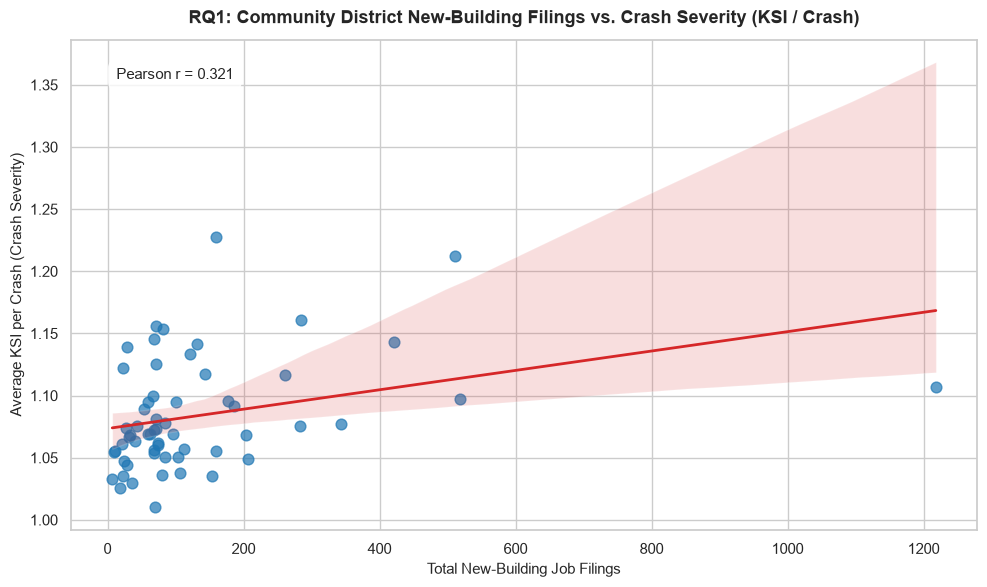

In [32]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.regplot(
    data=rq1_data,
    x='total_new_building_filings',
    y='ksi_per_crash',
    scatter_kws={'alpha': 0.7, 's': 60, 'color': '#1f77b4'},
    line_kws={'color': '#d62728', 'linewidth': 2},
    ax=ax
)

ax.set_title('RQ1: Community District New-Building Filings vs. Crash Severity (KSI / Crash)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Total New-Building Job Filings', fontsize=11)
ax.set_ylabel('Average KSI per Crash (Crash Severity)', fontsize=11)

# Annotate correlation coefficient
corr_rq1 = rq1_data['total_new_building_filings'].corr(rq1_data['ksi_per_crash'])
ax.text(0.05, 0.92, f'Pearson r = {corr_rq1:.3f}', transform=ax.transAxes, 
        fontsize=11, bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()

Core Finding: There is a weak-to-moderate positive linear correlation ($r = 0.321$) between district building filings and crash severity.   

Key Interpretation: While districts with heavier real estate development show slightly higher severe injury rates per crash on average, the overall trend is heavily pulled upward by a small number of extreme high-volume outlier districts (over 400 filings). For the vast majority of districts (under 200 filings), crash severity remains relatively flat between 1.02 and 1.15 KSI per crash.   

Why It Matters: Helps city agencies (NYC DOT, DOB) proactively target high-construction zones with site-specific safety infrastructure (e.g., temporary pedestrian barriers, delivery window restrictions) before building begins.

Cautions: Correlation does not prove causation. High-filing districts may simply be larger, denser commercial hubs. Unmeasured variables—such as vehicle speed, pedestrian density, and street width—are not accounted for in this single-variable correlation. 

## Research question 2
**Across the five boroughs, do year-to-year changes in proposed new housing units correspond to similar changes in KSI counts between 2022 and 2026?**

In [33]:
# Filter for temporal window 2022-2026
df_filtered = df_cd[(df_cd['year'] >= 2022) & (df_cd['year'] <= 2026)]

# Aggregate by Borough and Year
rq2_data = df_filtered.groupby(['borough', 'year']).agg(
    annual_proposed_units=('new_units', 'sum'),
    annual_ksi=('ksi', 'sum')
).reset_index()

# Sort to calculate YoY change correctly
rq2_data = rq2_data.sort_values(['borough', 'year'])

# Compute Year-over-Year (YoY) absolute changes
rq2_data['yoy_change_units'] = rq2_data.groupby('borough')['annual_proposed_units'].diff()
rq2_data['yoy_change_ksi'] = rq2_data.groupby('borough')['annual_ksi'].diff()

# Drop initial NaN year (2022 baseline for YoY diff)
rq2_diff = rq2_data.dropna(subset=['yoy_change_units', 'yoy_change_ksi'])

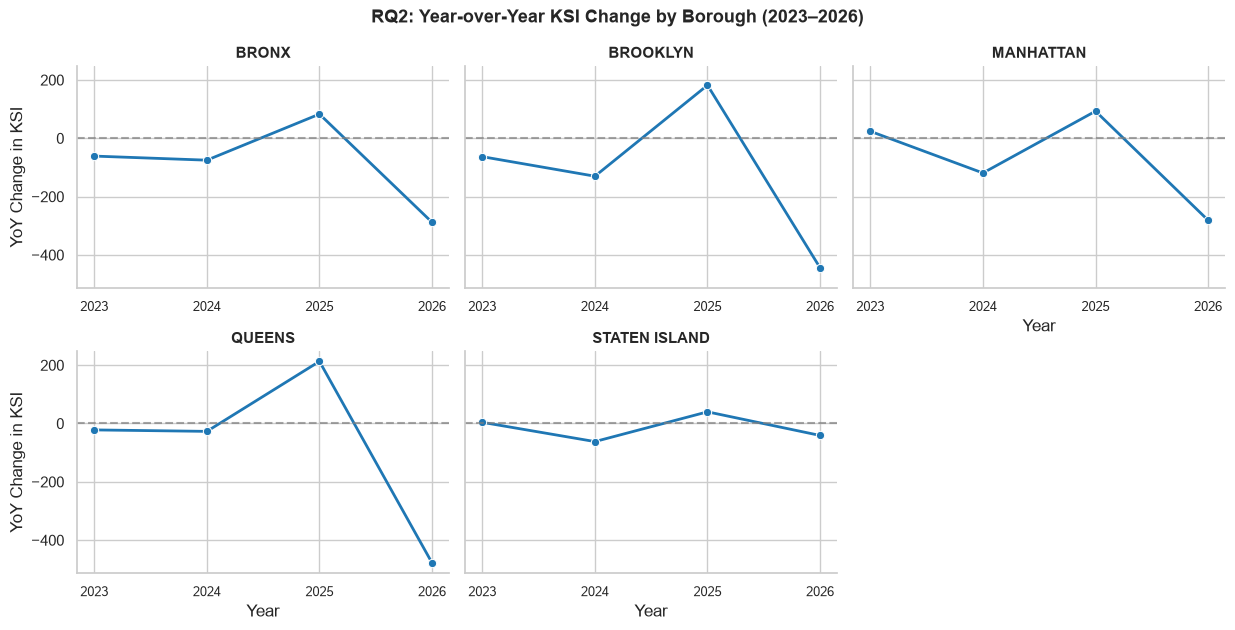

In [34]:
# 1. Create the small multiples grid
g = sns.FacetGrid(
    rq2_diff, 
    col="borough", 
    col_wrap=3, 
    height=3.2, 
    aspect=1.3, 
    sharey=True,
    sharex=False  # Allows year labels on every subplot
)

# 2. Map lineplot and baseline to each subplot
g.map(sns.lineplot, "year", "yoy_change_ksi", marker="o", color="#1f77b4", linewidth=2, markersize=6)
g.map(plt.axhline, y=0, color="gray", linestyle="--", alpha=0.7)

# 3. Explicitly set exact integer year ticks and display labels on ALL subplots
years = sorted(rq2_diff['year'].unique())
for ax in g.axes.flat:
    ax.set_xticks(years)
    ax.set_xticklabels([str(int(y)) for y in years], fontsize=9)
    ax.tick_params(labelbottom=True)  # Force X-axis tick labels on top-row plots too

# 4. Clean up titles and axis labels
g.set_axis_labels("Year", "YoY Change in KSI")
g.set_titles(col_template="{col_name}", size=11, weight='bold')
g.fig.subplots_adjust(top=0.85, hspace=0.35)
g.fig.suptitle("RQ2: Year-over-Year KSI Change by Borough (2023–2026)", fontsize=13, weight='bold')

plt.tight_layout()
plt.show()


Core Finding: Year-over-year (YoY) KSI changes display synchronized citywide macro-trends across all five boroughs, characterized by a sharp citywide peak in 2025 followed by a steep drop in 2026.

Key Interpretation: High-volume boroughs (Brooklyn and Queens) experienced the largest absolute positive spikes in 2025 (+180 and +210 YoY KSI). However, their largest overall shifts occurred in 2026, when both boroughs saw record single-year drops in severe injuries (~ -450 and ~ -480 YoY KSI).

Why It Matters: Demonstrates that severe traffic injuries are governed primarily by broad citywide factors (e.g., policy shifts, macro-traffic patterns) rather than isolated borough-by-borough development activity.

Cautions: Aggregating data at the borough level masks localized neighborhood-level spikes. Additionally, proposed housing units represent initial project filings, creating a multi-year time lag before physical construction or occupancy impacts local traffic.

**Summary**

Development vs. Severity (RQ1): Building filings do not inherently cause higher crash severity across most community districts. The slight positive correlation ($r = 0.321$) is heavily influenced by a few extreme high-construction outliers, while baseline crash severity remains steady across the vast majority of neighborhoods regardless of construction volume.

Macro vs. Local Trends (RQ2): Severe injury counts (KSI) move together in synchronized citywide macro-trends (peaking in 2025 and dropping sharply in 2026 across all five boroughs) rather than tracking localized, borough-specific housing development cycles.

**Impact**

City Agencies (DOT/DOB): Focus site-specific safety controls (delivery windows, pedestrian barriers) on extreme high-volume construction hotspots rather than imposing blanket zoning restrictions.

Community Boards: Avoid opposing new housing proposals on the assumption that development inherently increases severe traffic injuries.

Developers: Implement site safety logistics early to manage localized sidewalk and traffic disruption.

In [35]:
import os

# Create an output directory for figures if it doesn't exist
fig_dir = "../outputs/member1_housing"
os.makedirs(fig_dir, exist_ok=True)

# Save Plot 1 (RQ1)
# Add this right before plt.show() in the RQ1 visualization cell:
fig.savefig(os.path.join(fig_dir, "rq1_filings_vs_severity.png"), dpi=300, bbox_inches='tight')
fig.savefig(os.path.join(fig_dir, "rq1_filings_vs_severity.svg"), bbox_inches='tight')

# Save Plot 2 (RQ2)
# Add this right before plt.show() in the RQ2 visualization cell:
g.savefig(os.path.join(fig_dir, "rq2_yoy_ksi_borough.png"), dpi=300, bbox_inches='tight')
g.savefig(os.path.join(fig_dir, "rq2_yoy_ksi_borough.svg"), bbox_inches='tight')
